## Jorge Andrés Ceballos Cruz

## 1054867490

## 1. Fundamentos teoricos

## 1.1 Definición de dispersión


**Enunciado:** En el contexto de un modelo de regresión para predecir precios de casas, ¿por qué es insuficiente conocer solo la media de la variable median_house_value


La media solo indica el precio promedio central de las viviendas, pero no revela la variabilidad real de los datos. En un modelo de regresión, conocer únicamente este promedio es insuficiente porque dos zonas distintas pueden registrar el mismo precio medio, pero en una los costos pueden ser casi idénticos entre sí mientras que en la otra coexisten casas muy baratas con propiedades de lujo. La medida de dispersión es indispensable para entender la incertidumbre del mercado y permitir que el algoritmo mida la magnitud de sus posibles errores de predicción.

## 1.2 Varianza vs Desviación estandar

**Enunciado:** Explica la diferencia matemática entre ambas y
por qué en el análisis exploratorio de datos (EDA) preferimos la desviación estándar
para interpretar los precios de las viviendas.

**Respuesta:** La diferencia matemática es que la varianza calcula el promedio de las desviaciones elevadas al cuadrado, mientras que la desviación estándar es la raíz cuadrada de ese resultado. En el análisis exploratorio de datos (EDA) preferimos la desviación estándar porque devuelve la medida de dispersión a las mismas unidades de medida originales que estamos analizando. Esto nos permite interpretar de forma directa e intuitiva qué tanto se alejan los datos del promedio, a diferencia de la varianza, que al quedar expresada en unidades al cuadrado resulta abstracta e imposible de interpretar visualmente o en la vida real.

## 1.3 El problema de las unidades

**Enunciado:** Si calculamos la varianza de la variable population, ¿en
qué unidades queda expresado el resultado y qué problemas de interpretación acarrea
esto?

**Respuesta:** Al calcular la varianza de la variable population, el resultado queda expresado en "personas al cuadrado". El problema de interpretación es que esta unidad no tiene ningún sentido ni representación lógica en el mundo real. Al estar en una escala al cuadrado, no se puede comparar directamente con el valor de la media, lo que impide entender intuitivamente qué tan variados están los datos a menos que se le aplique la raíz cuadrada para convertirla en desviación estándar.

## 1.4 Coeficiente de Variación (CV)

**Enunciado:** Si la desviación estándar de median_income es 1.9
y la de median_house_value es 115,000, ¿cuál variable tiene una dispersión relativa
mayor? Define la fórmula del CV.

**Respuesta**:

La fórmula del Coeficiente de Variación es:

$$CV = \left( \frac{\sigma}{\mu} \right) \times 100\\%$$

Donde $\sigma$ es la desviación estándar y $\mu$ es la media de la variable.

Al calcular la dispersión relativa respecto a sus promedios, **`median_house_value` tiene una dispersión relativa mayor**. Su variación representa cerca del 55.6% respecto a su promedio, mientras que la de `median_income` representa alrededor del 49.1%. Esto ocurre porque el CV elimina el efecto de las escalas numéricas, permitiendo comparar correctamente variables que manejan magnitudes de dinero e ingreso totalmente diferentes.

## 1.5 Sensibilidad a Outliers:

**Enunciado:** ¿Cuál medida de dispersión es más robusta frente a errores de
medición en la variable households: la desviación estándar o el MAD (Median Absolute
Deviation)? ¿Por qué?

**Respuesta:** El MAD (Desviación Absoluta Respecto a la Mediana) es la medida más robusta frente a errores de medición porque utiliza la mediana, la cual no se altera por datos extremos, y mide distancias simples. En cambio, la desviación estándar se basa en la media y eleva las diferencias al cuadrado, provocando que un solo dato equivocado o extremadamente alto distorsione e infle por completo el resultado final.

## 1.6 Regla empirica (68-95-99.7)

**Enunciado:** Si el ingreso medio sigue una distribución aproximada-
mente normal, ¿qué porcentaje de la población se encuentra a más de dos desviaciones estándar de la media?

**Respuesta:** Según la Regla Empírica (68-95-99.7), aproximadamente el 95% de los datos se ubica dentro de dos desviaciones estándar respecto a la media. Por lo tanto, aproximadamente el 5% de la población se encuentra a más de dos desviaciones estándar del promedio, repartido por igual en un 2.5% en el extremo superior y un 2.5% en el extremo inferior de los datos.

## 1.7 Disperción y sesgo

**Enunciado:** Si observamos que la distancia entre el percentil 75 y el 100 es
mucho mayor que entre el 0 y el 25 en total_bedrooms, ¿qué nos dice esto sobre la
dispersión y la asimetría de los datos?

**Respuesta:** Esto nos indica que la variable presenta asimetría a la derecha (sesgo positivo) y una dispersión desigual. Significa que la gran mayoría de las propiedades tienen una cantidad baja o moderada de dormitorios, mientras que en el extremo superior existe un grupo reducido de inmuebles con un número muy elevado de habitaciones.

## 1.8 Estandarización (Z-score)

**Enunciado:** Explica cómo las medidas de dispersión se utilizan para
transformar una variable de modo que su media sea 0 y su desviación estándar sea 1.
¿Por qué es vital para algoritmos como SVM o KNN?

**Respuesta:** La estandarización resta la media a cada dato para centrar la variable en cero y la divide entre la desviación estándar para igualar su escala a uno. Esto es vital para algoritmos como KNN o SVM porque basan sus cálculos en distancias geométricas, si no se ajusta la dispersión, una variable con números de gran magnitud dominará por completo las distancias calculadas e ignorará a las variables con escalas más pequeñas, sin importar qué tan importantes sean para la predicción.

## 2. PRACTICA EN PYTHON

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv('housing.csv')

In [5]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


## 2.1 Implementación de Varianza

**Enunciado:** Sin usar .var(), calcula la varianza de median_income
aplicando la fórmula matemática paso a paso con NumPy.

In [6]:
# Obtener los valores de la columna como un arreglo de NumPy
x = df['median_income'].values

# Calcular la media de la variable
media = np.mean(x)

# Calcular las desviaciones respecto a la media
desviaciones = x - media

# Elevar las desviaciones al cuadrado
desviaciones_cuadradas = desviaciones ** 2

# Calcular la varianza muestral dividiendo la suma entre (N - 1)
varianza_manual = np.sum(desviaciones_cuadradas) / (len(x) - 1)

print(f"Varianza calculada manualmente: {varianza_manual:.4f}")

Varianza calculada manualmente: 3.6093


## 2.2 Comparación de Dispersión

**Enunciado:** Calcula la desviación estándar de total_rooms para las
casas cercanas al océano (NEAR OCEAN) vs. las casas tierra adentro (INLAND).
¿Dónde hay más diversidad de tamaños?

In [7]:
# Desviación estándar de total_rooms por categoría
std_near_ocean = df[df['ocean_proximity'] == 'NEAR OCEAN']['total_rooms'].std()
std_inland = df[df['ocean_proximity'] == 'INLAND']['total_rooms'].std()

print(f"Desviación estándar (NEAR OCEAN): {std_near_ocean:,.2f}")
print(f"Desviación estándar (INLAND): {std_inland:,.2f}")

Desviación estándar (NEAR OCEAN): 1,990.72
Desviación estándar (INLAND): 2,385.83


Las casas ubicadas tierra adentro (INLAND) presentan una mayor diversidad de tamaños, ya que su desviación estándar (2,385.83) es significativamente mayor que la de las zonas cercanas al océano (NEAR OCEAN) (1,990.72). Esto indica que lejos de la costa existe una variabilidad más amplia en el número de habitaciones por sector, abarcando desde comunidades pequeñas hasta conjuntos residenciales considerablemente más grandes.

## 2.3 Visualización (Boxplot)

**Enunciado:** Genera un diagrama de caja paramedian_house_value. Explica visualmente dónde se concentra el 50 % de los datos y dónde se encuentran los valores extremos.

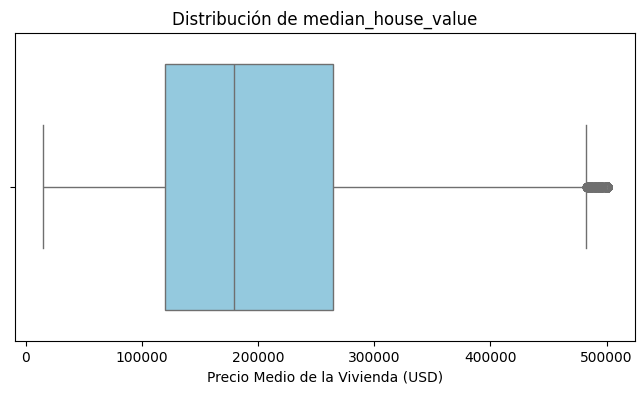

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del gráfico
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['median_house_value'], color='skyblue')

# Títulos y etiquetas
plt.title('Distribución de median_house_value')
plt.xlabel('Precio Medio de la Vivienda (USD)')
plt.show()

El 50 % central de las casas se concentra dentro de la caja azul, entre los $120,000 y $265,000, teniendo como punto medio unos $180,000 (la línea central). Por su parte, los valores extremos se observan a la derecha como un grupo de puntos amontonados en $500,000, lo que indica que hay muchas viviendas agrupadas en el precio máximo registrado por el dataset

## 2.4 Análisis de Variable Crítica

**Enunciado:** Calcula el Coeficiente de Variación para total_bedrooms.
Si el resultado es mayor a 1 (o 100 %), ¿qué indica esto sobre la confiabilidad de la
media como medida de tendencia central?

In [9]:
# Cálculo del Coeficiente de Variación para total_bedrooms
media_tb = df['total_bedrooms'].mean()
std_tb = df['total_bedrooms'].std()
cv_tb = (std_tb / media_tb) * 100

print(f"Media: {media_tb:.2f}")
print(f"Desviación Estándar: {std_tb:.2f}")
print(f"Coeficiente de Variación: {cv_tb:.2f}% (o {std_tb / media_tb:.2f})")

Media: 537.87
Desviación Estándar: 421.39
Coeficiente de Variación: 78.34% (o 0.78)


El Coeficiente de Variación obtenido es de 78.34% (0.78), lo que indica una variabilidad alta en la cantidad de dormitorios pero sin llegar a superar el límite del 100%. Si este indicador fuera mayor a 1 (100%), significaría que la desviación estándar supera a la propia media, revelando una dispersión extrema causada por datos atípicos o un fuerte sesgo a la derecha; en dicho escenario, la media pierde confiabilidad como valor representativo de la población, haciendo necesario recurrir a la mediana como medida central más robusta.

## 2.5 Matriz de Covarianza

**Enunciado:** Utiliza df.cov() para observar la relación de dispersión conjunta
entre total_rooms y total_bedrooms. ¿Qué significa un valor de covarianza positivo
alto en este contexto?

In [10]:
# Covarianza conjunta entre total_rooms y total_bedrooms
cov_matrix = df[['total_rooms', 'total_bedrooms']].cov()
print(cov_matrix)

                 total_rooms  total_bedrooms
total_rooms     4.759445e+06   856730.634823
total_bedrooms  8.567306e+05   177565.377281


La covarianza positiva y alta (856,730.63) confirma una relación directa: a mayor número de habitaciones en una zona, mayor es la cantidad de dormitorios. Esto refleja sencillamente que los inmuebles más grandes amplían sus espacios aumentando también la cantidad de recámaras de forma proporcional.

## 2.6 Transformación de Datos

**Enunciado:** Aplica un StandardScaler (de sklearn) o realiza manualmente
la estandarización de median_house_value. Verifica que la nueva desviación estándar
sea efectivamente 1.

In [11]:
from sklearn.preprocessing import StandardScaler

# Crear el objeto escalador y transformar la variable
scaler = StandardScaler()
df['median_house_value_z'] = scaler.fit_transform(df[['median_house_value']])

#  Verificar la nueva media (debe ser cercana a 0) y desviación estándar (debe ser 1)
media_z = df['median_house_value_z'].mean()
std_z = df['median_house_value_z'].std()

print(f"Nueva Media: {media_z:.4f} (prácticamente 0)")
print(f"Nueva Desviación Estándar: {std_z:.4f}")

Nueva Media: -0.0000 (prácticamente 0)
Nueva Desviación Estándar: 1.0000


El resultado confirma que la estandarización fue exitosa. Al obtener una desviación estándar de 1.0000 y una media de 0, la variable median_house_value quedó transformada a la escala de puntajes Z (Z-scores).

## 2.7 Efecto de la limpieza

Elimina los valores nulos de total_bedrooms y recalcula la
desviación estándar. ¿Cambió significativamente la dispersión? Justifica por qué el
tratamiento de datos faltantes afecta las medidas de dispersión.

In [12]:
# Desviación estándar original y eliminando nulos
std_original = df['total_bedrooms'].std()
std_limpia = df['total_bedrooms'].dropna().std()

print(f"Desviación estándar original: {std_original:.2f}")
print(f"Desviación estándar sin nulos: {std_limpia:.2f}")

Desviación estándar original: 421.39
Desviación estándar sin nulos: 421.39


La desviación estándar se mantuvo exactamente igual (421.39) debido a que Pandas omite los valores nulos por defecto y la proporción de vacíos es insignificante frente al total del dataset. El tratamiento de datos faltantes impacta las medidas de dispersión porque imputar valores con la media reduce artificialmente la variabilidad al concentrar datos en el centro, mientras que eliminar registros puede alterar la diversidad real de la muestra si los nulos no ocurrieron de forma totalmente aleatoria.